**Nawaf Khalid Alsabr**  
**ID: 2230004159**

# Lab2: Text Pre-processing and Regular Expressions

 In this lab, you will learn essential techniques for preparing and cleaning text data using various pre-processing steps. Additionally, you will gain hands-on experience with regular expressions, a powerful tool for pattern matching and text manipulation in natural language processing (NLP) tasks.

_____________________________________________________________________________________________

## Regular Expressions

Regular expressions (regex) are extremely useful in extracting information from any text by searching for one or more matches of a specific search pattern

https://www.regexpal.com/

#### Regular Expressions use cases

- Data pre-processing
- Pattern matching
- Text feature Engineering
- Web scraping
- Data validation
- Data extraction

An example use case is extracting all hashtags from a tweet, or getting email addresses or phone numbers from large unstructured text content.

## Regular Expressions with Python

Python provides a convenient built-in module for managing regular expressions:

> import re

We can import it as we import any other Python library.

### Important symbols in Regular Expression

Let’s start with the basic regular expression characters and some examples:

- (^) : Matches the expression to its right, at the start of a string before it finds a line break.
- ($) : Matches the expression to its left, at the end of a string before it finds a line break.
- (.) : Matches any character except newline.
- (a) : Matches exactly one character.
- (ab) : Matches the string ab.

----------------------------------------------------------------------------
Quantifiers:

- (a|b) : Matches expression a or b. If a is matched first, b is not checked;
- (+) : Matches the expression to its left 1 or more times;
- (*) : Matches the expression to its left 0 or more times;
- (?) : Matches the expression to its left 0 or 1 times.
----------------------------------------------------------------------------
Character Classes:

- \w : Matches alphanumeric characters, that is a-z, A-Z, 0–9, and underscore(_);
- \W : Matches non-alphanumeric characters, that is except a-z, A-Z, 0–9, and _;
- \d : Matches digits, from 0–9;
- \D : Matches any non-digits;
- \s : Matches whitespace characters, which also include the \t, \n, \r, and space characters;
- \S : Matches non-whitespace characters.
- \n : Matches a newline character;
- \t : Matches a tab character;
- \b : Matches the word boundary (or empty string) at the start and end of a word;
- \B : Matches where \b does not, that is non-word boundary.

----------------------------------------------------------------------------
Sets:

- [abc] : Matches either a, b, or c. It does not match abc;
- [a-z] : Matches any alphabet from a to z;
- [A-Z] : Matches any alphabets in capital from A to Z;
- [a\-p] : Matches a, -, or p. It matches - because \ escapes it;
- [-z] : Matches - or z;
- [a-z0–9] : Matches characters from a to z or from 0 to 9.
- [(+*)] : Special characters become literal inside a set, so this matches (, +, *, or );
- [^ab5] : Adding ^ excludes any character in the set. Here, it matches characters that are not a, b, or 5;
----------------------------------------------------------------------------


### Regular Expression functions



In [1]:
import re

text = "Woodchucks is another name for groundhog!"

re.findall(r"groundhog|woodchuck",text)

['groundhog']

#### search

Search for pattern occurrences in a string using the search function of the **re module**. This function returns a match object, containing the first matched substring (or None, if it doesn’t exist) and its position inside the original string.

In [2]:
import re

text = 'I am enjoying the NLP course.'

print(re.search(r"I", text)) #r"I" means it's a raw string literal
print(re.search(r"se.$", text)) #$ Search at the end of the string
print(re.search(r"am", text))
print(re.search(r"m", text))
print(re.search(r"AI", text))

<re.Match object; span=(0, 1), match='I'>
<re.Match object; span=(26, 29), match='se.'>
<re.Match object; span=(2, 4), match='am'>
<re.Match object; span=(3, 4), match='m'>
None


In [3]:
match = re.search((r"I"),text)
print(match.span())
print(match.start())
print(match.end())
print("The matched pattern is: ",text[match.start():match.end()]) #return matched string using index from text
print("The matched pattern is: ", match.group()) #return matched string using group() method

(0, 1)
0
1
The matched pattern is:  I
The matched pattern is:  I


#### match

The match function is similar to search, but it only tries to match the pattern at the beginning of the target string.

In [4]:
import re
re.match?

In [5]:
import re

text = 'I am enjoying the NLP course.'

print(re.search(r"I.*", text)) #global
print(re.match(r"I.*", text)) #local >> search at the start of the string

print(re.search(r"enjoying.*", text))
print(re.match(r"enjoying.*", text))

<re.Match object; span=(0, 29), match='I am enjoying the NLP course.'>
<re.Match object; span=(0, 29), match='I am enjoying the NLP course.'>
<re.Match object; span=(5, 29), match='enjoying the NLP course.'>
None


In [6]:
import re

text = '1999 was the year I was born.'

print(re.search(r"[a-zA-Z]+", text))
print(re.match(r"[a-zA-Z]+", text))

<re.Match object; span=(5, 8), match='was'>
None


Search does a global search, whereas match does a local search!

**Match** is often used when you need to check if the string starts with a specific pattern.


**Search** is used when you want to find a pattern anywhere within the string.

#### findall

The findall function looks for all the pattern matches in the target string (whereas search and match look only for the first occurrence).

- `re.findall()` returns a list of all matches.

- `re.finditer()` returns an iterator of match objects.

- `re.search() and re.match()` both return a single match object for the first occurrence (but differ in where they start matching: match() matches only at the start of the string, search() anywhere).

In [7]:
import re

text1 = "a 1 b 2 c 3"
text2 = "a1 b2 c 3"
text3 = "a 1 b 222 c 3"

print(re.findall(r"\d+", text1)) #match any digit
print(re.findall(r"\d+", text2))
print(re.findall(r"\d+", text3))

['1', '2', '3']
['1', '2', '3']
['1', '222', '3']


#### sub

The sub is a function that finds patterns in the target string and substitute them with another string.

flags=re.I --> non-case-sensitive

count = specify number of matches you want to replace

In [8]:
import re

re.sub?

In [9]:
import re

text = 'I am enjoying the Math course.'

print(re.sub(r"Math", "NLP", text, count=1, flags=re.I)) #flags=re.I >> Ignore the case (no matter if M or m)
                                                 # count = 1 >> number of word I need it to change. count= 0 by default

I am enjoying the NLP course.


#### compile

The compile function compiles a regular expression into a regular expression object, which allows for caching and faster pattern matching.

In [10]:
import re
re.compile?

In [11]:
import re

text = "This year is 2021"
pattern = re.compile(r"\d+")
print(type(pattern))

print(pattern.sub("2022", text))

<class 're.Pattern'>
This year is 2022


#### split

The split function is similar to the Python split function, but splits according to regular expression patterns.

In [12]:
string = 'Apple,Orange,Mango,Banana'
print(string.split(','))

['Apple', 'Orange', 'Mango', 'Banana']


In [13]:
import re

text = "a 1 b 2 c 3"

print(re.split(r"\d+", text))

text = "a 11 b 2 3 c 4"

print(re.split(r"\d+", text))

['a ', ' b ', ' c ', '']
['a ', ' b ', ' ', ' c ', '']


__________________________________________________________________________

## Text pre-processing steps


Text preprocessing involves transforming text into a clean and consistent format that can then be fed into a model for further analysis and learning. Raw text data might contain unwanted or unimportant text due to which our results might not give efficient accuracy, and might make it hard to understand and analyze.

**The various text preprocessing steps are:**

1. Tokenization.
2. Lower casing.
3. Stop words removal.
4. Stemming.
5. Lemmatization.

Before implementing the pre-processing, let us understand the concept first.

### Tokenization

Tokenization is used in NLP to split paragraphs and sentences into smaller units that can be more easily assigned meaning.

The first step of the NLP process is gathering the data (a sentence) and breaking it into understandable parts (words).

- **Sentence Tokenization**

In [14]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Error loading punkt: Security Violation [pathsec.urlopen]:
[nltk_data]     refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt_tab: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

False

In [15]:
import nltk

text = "I'm enjoying the NLP course! I am also learning new concepts."

print(nltk.sent_tokenize(text))

["I'm enjoying the NLP course!", 'I am also learning new concepts.']


- **Word Tokenzitaion**

In [16]:
text = "I'm enjoying the NLP course!"
text.split()

["I'm", 'enjoying', 'the', 'NLP', 'course!']

In [17]:
import nltk

text = "I'm enjoying the NLP course!"

print(nltk.word_tokenize(text)) #I'm is tokenized to two tokens [I,m] course! is also tokenized to two tokens [course,!]

['I', "'m", 'enjoying', 'the', 'NLP', 'course', '!']


In [18]:
!pip install -U spacy -q
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [19]:
import spacy
nlp = spacy.load('en_core_web_sm') # Load the small English model - - nlp becomes a pipeline you can use to process text (e.g., tokenize, tag, parse).

doc = nlp("I'm enjoying the NLP course!") # Process the text using nlp model, returns Doc object.

for token in doc: # Iterate over each token in the Doc object.
    print(token)

I
'm
enjoying
the
NLP
course
!


In [20]:
text = "A 5km NYC cab ride costs $10.30"
doc = nlp("A 5km NYC cab ride costs $10.30")

print('nltk Tokenizer result: ')
print(nltk.word_tokenize(text))

print('\nSpaCy Tokenizer result: ')

for token in doc:
    print(token)

nltk Tokenizer result: 
['A', '5km', 'NYC', 'cab', 'ride', 'costs', '$', '10.30']

SpaCy Tokenizer result: 
A
5
km
NYC
cab
ride
costs
$
10.30


### Lower Casting

Converting a word to lower case (NLP -> nlp). Words like Book and book mean the same but when not converted to the lower case those two are represented as two different words in the vector space model (resulting in more dimensions).

In [21]:
text = "I'm enjoying the NLP course!"
text = text.lower()
text

"i'm enjoying the nlp course!"

### Stemming

Stemming is basically removing the suffix from a word and reduce it to its root word. For example: “Flying” is a word and its suffix is “ing”, if we remove “ing” from “Flying” then we will get base word or root word which is “Fly”. We uses these suffix to create a new word from original stem word.

https://www.nltk.org/howto/stem.html

#### What is PorterStemmer?

It is one of the most popular stemming methods proposed in 1980. It is based on the idea that the suffixes in the English language are made up of a combination of smaller and simpler suffixes. This stemmer is known for its speed and simplicity. The main applications of Porter Stemmer include data mining and Information retrieval. However, its applications are only limited to English words. Also, the group of stems is mapped on to the same stem and the output stem is not necessarily a meaningful word. The algorithms are fairly lengthy in nature and are known to be the oldest stemmer.

> Advantage: It produces the best output as compared to other stemmers and it has less error rate.

> Limitation:  Morphological variants produced are not always real words.

In [22]:
import nltk
from nltk.stem import PorterStemmer

ps = PorterStemmer() # create a PorterStemmer object

words = ['run','runner','running','ran','runs','easily','fairly']

for word in words:
    print(word + ' --> ' + ps.stem(word))

run --> run
runner --> runner
running --> run
ran --> ran
runs --> run
easily --> easili
fairly --> fairli


#### What is SnowballStemmer?

It is a stemming algorithm which is also known as the Porter2 stemming algorithm as it is a better version of the Porter Stemmer since some issues of it were fixed in this stemmer.

> Advantage: It is slightly faster computation time than porter, with a reasonably large community around it.

In [23]:
import nltk
from nltk.stem.snowball import SnowballStemmer

sn = SnowballStemmer(language='english')

words = ['run','runner','running','ran','runs','easily','fairly']

for word in words:
    print(word+' --> '+sn.stem(word))

run --> run
runner --> runner
running --> run
ran --> ran
runs --> run
easily --> easili
fairly --> fair


#### Comparing between porter and snowball

In [24]:
words = ['generous','generation','generously','generate']

for word in words:
    print(word+' --> '+ps.stem(word))
    print(word+' --> '+sn.stem(word))
    print('---------------------------------------')

generous --> gener
generous --> generous
---------------------------------------
generation --> gener
generation --> generat
---------------------------------------
generously --> gener
generously --> generous
---------------------------------------
generate --> gener
generate --> generat
---------------------------------------


**Note**: Spacy does not provide stemming

### Lemmatization

Lemmatization is the process of grouping together the different inflected forms of a word so they can be analyzed as a single item. Lemmatization is similar to stemming but it brings context to the words. So it links words with similar meanings to one word.

> One major difference with stemming is that lemmatize takes a part of speech parameter (pos) If not supplied, the default is “noun.”

| Part of Speech          | Description                | Example Words           |
| ----------------------- | -------------------------- | ----------------------- |
| **Noun (N)**            | Person, place, thing, idea | dog, city, love, Python |
| **Verb (V)**            | Action or state            | run, eat, is, was, jump |
| **Adjective (ADJ)**     | Describes a noun           | happy, blue, fast       |
| **Adverb (ADV)**        | Describes a verb/adjective | quickly, very, well     |
| **Pronoun (PRON)**      | Replaces a noun            | he, she, it, they       |
| **Preposition (ADP)**   | Shows relationship         | in, on, under, with     |
| **Conjunction (CONJ)**  | Connects words/clauses     | and, but, or            |
| **Determiner (DET)**    | Introduces a noun          | a, an, the              |
| **Interjection (INTJ)** | Expresses emotion          | wow, oh, hey            |


In [25]:
nltk.download('wordnet')

[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


False

In [26]:
import nltk
from nltk.stem import WordNetLemmatizer

text = 'I am enjoying AI courses. I am taking NLP course.'
lemmatizer = WordNetLemmatizer()

for word in nltk.word_tokenize(text):
    print(f"{word}: ", lemmatizer.lemmatize(word))

I:  I
am:  am
enjoying:  enjoying
AI:  AI
courses:  course
.:  .
I:  I
am:  am
taking:  taking
NLP:  NLP
course:  course
.:  .


In [27]:
# Changing pos to verb
for word in nltk.word_tokenize(text):
    print(f"{word}: ", lemmatizer.lemmatize(word, pos='v'))

I:  I
am:  be
enjoying:  enjoy
AI:  AI
courses:  course
.:  .
I:  I
am:  be
taking:  take
NLP:  NLP
course:  course
.:  .


You may go through Spacy's lemmatizer: https://spacy.io/api/lemmatizer

### ٍStop Words Removal

The words which are generally filtered out before processing a natural language are called stop words. These are actually the most common words in any language (like articles, prepositions, pronouns, conjunctions, etc) and does not add much information to the text. Examples of a few stop words in English are “the”, “a”, “an”, “so”, “what”.

#### Why do we need to remove stopwords?

By removing these words, we remove the low-level information from our text in order to give more focus to the important information. In order words, we can say that the removal of such words does not show any negative consequences on the model we train for our task.

- reduces the dataset size
- reduces the training time

#### Do we always remove stopwords? **NO!**

We do not always remove the stop words. The removal of stop words is highly dependent on the task we are performing and the goal we want to achieve. For example, if we are training a model that can perform the sentiment analysis task, we might not remove the stop words.

Movie review: “The movie was not good at all.”

Text after removal of stop words: “movie good”

In [28]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [29]:
print(nlp.Defaults.stop_words)
print(len(nlp.Defaults.stop_words))

{'third', 'hereby', 'hence', 'herein', 'along', 'per', 'enough', 'our', 'during', 'noone', "'s", 'itself', 'every', 'well', 'beside', 'he', 'had', 'regarding', 'whereby', 'much', 'against', 'too', 'thru', 'side', 'been', 'someone', 'once', 'than', 'with', 'whence', 'done', 'other', '’d', 'throughout', 'towards', 'twelve', 'below', 'i', 'five', '’s', 'more', 'for', 'how', 'am', 'whereafter', 'whole', '’ve', 'under', 'only', 'twenty', 'anyway', 'even', 'since', 'already', 'perhaps', 'therein', 'beyond', 'via', 'up', 'wherever', 'very', 'of', 'we', 'was', 'formerly', 'those', 'else', 'another', 'again', 'or', 'behind', 'serious', 'anyone', 'beforehand', 'why', 'should', 'nevertheless', 'each', 'who', 'nine', 'whither', 'by', 'least', 'mine', 'ten', 'where', "'d", 'seemed', 'whether', 'put', 'empty', 'front', 'together', 'him', 'this', 'full', 'through', 'call', 'must', 'show', 'before', 'give', 'last', 'toward', 'would', 'us', 'my', 'afterwards', 'everything', 'hereafter', 'whom', 'until'

In [30]:
print(nlp.vocab['myself'].is_stop)
print(nlp.vocab['mystery'].is_stop)

True
False


In [31]:
print (nlp.vocab['btw'].is_stop) #print False

False


In [32]:
nlp.Defaults.stop_words.add('btw')

nlp.vocab['btw'].is_stop = True # You must update the is_stop flag for the word you added

print (nlp.vocab['btw'].is_stop)

True


In [33]:
nlp.Defaults.stop_words.remove('beyond')
nlp.vocab['beyond'].is_stop = False

print(nlp.vocab['beyond'].is_stop)

False


### Stop words in NLTK

In [34]:
import nltk
nltk.download('stopwords')

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


False

In [35]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
print(len(stop_words))

198


_________________________________________________________________________________________________________

# Text pre-processing Example

To make you understand better about the need of text pre-processing. We will do a small project. In this project, I need to find how many hashtags and the top 10 hashtags used in the dataset.

The dataset is about people tweets about apple company in the twitter. You can find the dataset here:

https://www.kaggle.com/datasets/seriousran/appletwittersentimenttexts


## Mini Project: Hashtag Extraction with Regular Expressions

**Goal:** Using the Apple Twitter Sentiment dataset (tweets about Apple), find:
1. How many hashtags appear in total across the dataset
2. The top 10 most frequently used hashtags

We'll use a regular expression to extract hashtags (a `#` followed by one or more word characters) from each tweet.


In [36]:
import pandas as pd
import re
from collections import Counter

# Load the Apple Twitter Sentiment dataset
df = pd.read_csv("apple-twitter-sentiment-texts.csv")
df.head()


,text,sentiment
0,Wow. Yall needa step it up @Apple RT @heynyla:...,-1
1,What Happened To Apple Inc? http://t.co/FJEX...,0
2,Thank u @apple I can now compile all of the pi...,1
3,The oddly uplifting story of the Apple co-foun...,0
4,@apple can i exchange my iphone for a differen...,0


In [37]:
# Extract all hashtags from each tweet using a regular expression
# A hashtag is '#' followed by one or more word characters (letters, digits, underscore)
hashtag_pattern = re.compile(r"#\w+")

df['hashtags'] = df['text'].astype(str).apply(lambda t: hashtag_pattern.findall(t))

# Flatten the list of hashtags into a single list (normalize to lowercase so 'AAPL' and 'aapl' count together)
all_hashtags = [tag.lower() for tags in df['hashtags'] for tag in tags]

print(f"Total number of hashtags found: {len(all_hashtags)}")
print(f"Number of unique hashtags: {len(set(all_hashtags))}")


Total number of hashtags found: 1616
Number of unique hashtags: 555


In [38]:
# Find the top 10 most common hashtags
hashtag_counts = Counter(all_hashtags)
top_10 = hashtag_counts.most_common(10)

print("Top 10 hashtags:")
for rank, (tag, count) in enumerate(top_10, start=1):
    print(f"{rank}. {tag} — {count} occurrences")


Top 10 hashtags:
1. #aapl — 400 occurrences
2. #apple — 162 occurrences
3. #iphone — 38 occurrences
4. #december — 37 occurrences
5. #iphone6 — 29 occurrences
6. #stocks — 15 occurrences
7. #ipad — 14 occurrences
8. #iphone6plus — 13 occurrences
9. #iphone6s — 13 occurrences
10. #tech — 12 occurrences


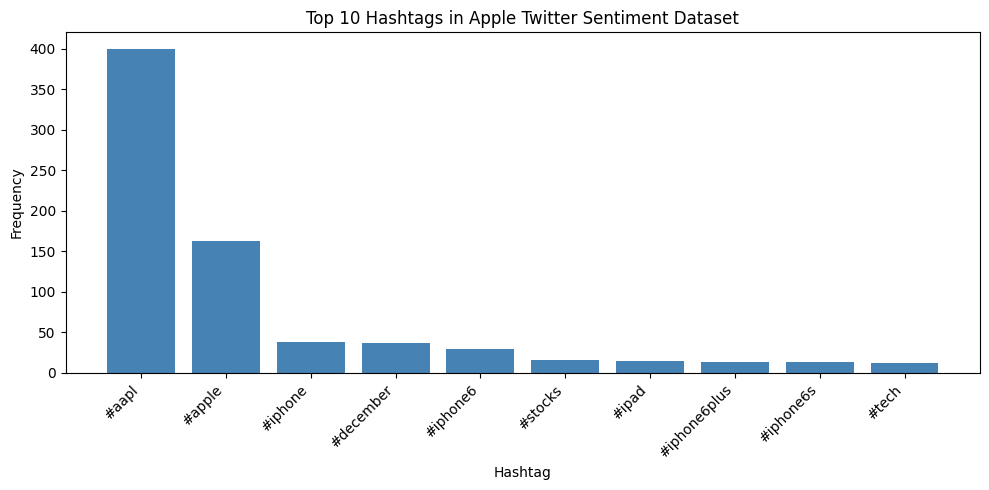

In [39]:
import matplotlib.pyplot as plt

tags, counts = zip(*top_10)

plt.figure(figsize=(10, 5))
plt.bar(tags, counts, color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.xlabel('Hashtag')
plt.ylabel('Frequency')
plt.title('Top 10 Hashtags in Apple Twitter Sentiment Dataset')
plt.tight_layout()
plt.show()


**Conclusion:** Regular expressions made it straightforward to extract every hashtag from the raw tweet text in a single pass (`#\w+`), without needing full tokenization. Normalizing to lowercase avoided double-counting hashtags that differ only in case (e.g., `#AAPL` vs `#aapl`). As expected for a dataset of Apple-related tweets, hashtags referencing Apple, its products, and its stock ticker dominate the top 10.